In [1]:
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
# Permite importar el paquete de src/ sin instalarlo
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

# 05 · Torneo de modelos

Este notebook **solo orquesta**: los candidatos, el `Pipeline`, las métricas y las comparaciones están en
`src/tarifalatam/models/train.py`, con sus pruebas en `tests/test_train.py`.

**Reglas escritas antes de medir** (`especificaciones/04-features-torneo-optimizacion.md`, sección 5, aprobada el
2026-10-31):

1. **Mismos datos, mismas variables y mismos pliegues para todos:** los pliegues de `data/processed/folds.csv` (no se
   recalculan) y las variables que decidió la etapa 4 (`config.FINAL_IDEAS`), **sin columnas sospechosas**.
2. **Una línea base** que cualquier modelo serio debe vencer: la mediana por ciudad × tipo de habitación.
3. **Métrica principal: MAE en USD por noche.** Técnicas: MAPE, R² (sobre el logaritmo), RMSE y sesgo medio. Además, el error
   por ciudad.
4. **Se guarda cada pliegue**, no solo el promedio, para comparar de a pares.
5. El torneo **elige 1–2 finalistas, no un campeón**: la optimización puede cambiar el orden.

**La prueba no se abre.** **Salidas:** `reports/05_torneo_tabla.csv` (modelo × pliegue) y `reports/05_torneo_por_ciudad.csv`
(modelo × pliegue × ciudad).

## 0. Datos, pliegues y variables

In [2]:
from tarifalatam import config
from tarifalatam.config import GROUP_COL, REPORTS_DIR, TARGET
from tarifalatam.data.folds import fold_indices, load_folds
from tarifalatam.data.load import load_train
from tarifalatam.models.train import feature_frame

train = load_train()
fold_pairs = fold_indices(train, load_folds())  # los mismos del notebook 04; se detiene si no coinciden
X, y = feature_frame(train), train[TARGET].to_numpy()
ideas = config.FINAL_IDEAS  # decididas en la etapa 4 (reports/04_features.md)
print(f"entrenamiento: {len(train):,} anuncios · {train[GROUP_COL].nunique():,} anfitriones · {len(fold_pairs)} pliegues")
print("ideas de la etapa 4:", ideas or "ninguna: se usa la referencia (13 columnas)")

entrenamiento: 118,513 anuncios · 53,385 anfitriones · 5 pliegues
ideas de la etapa 4: ninguna: se usa la referencia (13 columnas)


## 1. Los candidatos (parámetros razonables, sin optimizar)

| Candidato | Configuración | Preprocesamiento |
|---|---|---|
| `linea_base` | Mediana de `price_usd` por `city` × `room_type` (la de H1) | Ninguno |
| `ridge` | `Ridge(alpha=1.0)` sobre `log(price_usd)` | Imputación, escalado y one-hot (categorías raras → "Other") |
| `random_forest` | `RandomForestRegressor(n_estimators=200, min_samples_leaf=3, max_features=0.5)` | Imputación y codificación ordinal |
| `lightgbm` | `LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=31)` (el mismo de la etapa 4) | Codificación ordinal; los vacíos los maneja el modelo |

In [3]:
from tarifalatam.models.train import build_pipeline, candidates, city_errors, evaluate_folds

per_fold, per_city = [], []
for name, (model, family) in candidates().items():
    start = time.perf_counter()
    table, oof = evaluate_folds(build_pipeline(model, family, ideas=ideas), X, y, fold_pairs)
    per_fold.append(table.assign(model=name))
    per_city.append(city_errors(train["city"], y, oof, fold_pairs).assign(model=name))
    print(f"{name:14s} MAE {table['mae'].mean():6.2f} ± {table['mae'].std():4.2f} USD · {time.perf_counter() - start:5.0f} s")
per_fold = pd.concat(per_fold, ignore_index=True)
per_city = pd.concat(per_city, ignore_index=True)

linea_base     MAE  55.90 ± 2.55 USD ·     1 s


ridge          MAE  43.64 ± 1.88 USD ·     3 s


random_forest  MAE  39.67 ± 1.60 USD ·    18 s


lightgbm       MAE  39.90 ± 1.73 USD ·     3 s


## 2. Métrica de negocio y métricas técnicas

Media ± desviación entre los 5 pliegues. **Sesgo** = promedio de (predicho − real): negativo significa que el modelo
**subestima** en promedio; positivo, que sobrestima (el error más caro para el inversionista).

In [4]:
summary = per_fold.groupby("model")[["mae", "mape", "rmse", "bias", "r2_log", "fit_seconds"]].agg(["mean", "std"])
business = pd.DataFrame({
    "MAE (USD)": summary[("mae", "mean")],
    "± entre pliegues": summary[("mae", "std")],
    "mejor pliegue": per_fold.groupby("model")["mae"].min(),
    "peor pliegue": per_fold.groupby("model")["mae"].max(),
    "segundos de ajuste (por pliegue)": summary[("fit_seconds", "mean")],
}).sort_values("MAE (USD)")
order = list(business.index)
display(business.round(2))

technical = pd.DataFrame({
    "MAPE (%)": summary[("mape", "mean")],
    "R² (log)": summary[("r2_log", "mean")],
    "RMSE (USD)": summary[("rmse", "mean")],
    "sesgo (USD)": summary[("bias", "mean")],
}).loc[order]
display(technical.round(3))

ranks = pd.DataFrame({
    "MAE": business["MAE (USD)"].rank(),
    "MAPE": technical["MAPE (%)"].rank(),
    "R² (log)": technical["R² (log)"].rank(ascending=False),
    "RMSE": technical["RMSE (USD)"].rank(),
    "|sesgo|": technical["sesgo (USD)"].abs().rank(),
}).astype(int)
print("Posiciones por métrica (1 = mejor):")
display(ranks)

,MAE (USD),± entre pliegues,mejor pliegue,peor pliegue,segundos de ajuste (por pliegue)
model,,,,,
random_forest,39.67,1.60,38.18,42.12,3.48
lightgbm,39.90,1.73,38.29,42.47,0.59
ridge,43.64,1.88,41.80,45.93,0.55
linea_base,55.90,2.55,53.17,58.91,0.07


,MAPE (%),R² (log),RMSE (USD),sesgo (USD)
model,,,,
random_forest,32.776,0.638,110.517,-13.005
lightgbm,32.704,0.636,111.045,-14.028
ridge,37.075,0.569,121.939,-15.414
linea_base,43.536,0.278,152.899,-32.639


Posiciones por métrica (1 = mejor):


,MAE,MAPE,R² (log),RMSE,|sesgo|
model,,,,,
random_forest,1,2,1,1,1
lightgbm,2,1,2,2,2
ridge,3,3,3,3,3
linea_base,4,4,4,4,4


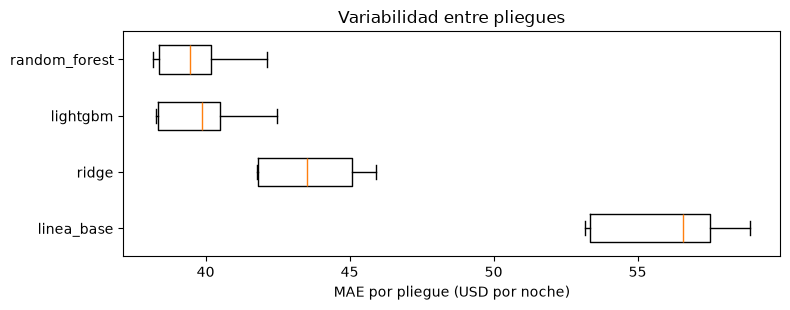

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.boxplot([per_fold.loc[per_fold["model"] == m, "mae"] for m in order], vert=False, tick_labels=order, widths=0.5)
ax.invert_yaxis()
ax.set_xlabel("MAE por pliegue (USD por noche)")
ax.set_title("Variabilidad entre pliegues")
plt.tight_layout()
plt.show()

## 3. Error por ciudad

MAE y sesgo medios por ciudad (promedio de los 5 pliegues). Belice tiene pocos anuncios (2.604 en el entrenamiento): su cifra
es la más ruidosa.

In [6]:
city_mae = per_city.pivot_table(index="model", columns="city", values="mae", aggfunc="mean").loc[order]
city_bias = per_city.pivot_table(index="model", columns="city", values="bias", aggfunc="mean").loc[order]
print("MAE por ciudad (USD):")
display(city_mae.round(2))
print("Sesgo por ciudad (USD):")
display(city_bias.round(2))
print("Anuncios de validación por ciudad (promedio por pliegue):")
display(per_city[per_city["model"] == order[0]].groupby("city")["n"].mean().round(0).to_frame().T)

MAE por ciudad (USD):


city,belize,bogota,mexico-city,rio-de-janeiro,santiago,sao-paulo
model,,,,,,
random_forest,204.10,24.05,41.74,55.48,22.69,22.12
lightgbm,206.49,24.03,41.80,55.38,23.78,22.40
ridge,226.49,27.53,46.80,59.99,25.01,24.46
linea_base,316.13,32.04,56.48,75.35,43.80,29.12


Sesgo por ciudad (USD):


city,belize,bogota,mexico-city,rio-de-janeiro,santiago,sao-paulo
model,,,,,,
random_forest,-72.92,-6.99,-13.17,-20.41,-6.42,-5.82
lightgbm,-82.71,-7.63,-14.23,-21.35,-7.24,-6.47
ridge,-84.41,-6.59,-14.52,-25.27,-6.95,-7.61
linea_base,-192.76,-18.29,-30.98,-46.75,-28.29,-13.88


Anuncios de validación por ciudad (promedio por pliegue):


city,belize,bogota,mexico-city,rio-de-janeiro,santiago,sao-paulo
n,521.0,2441.0,4458.0,6818.0,2826.0,6639.0


## 4. Comparación pareada de los tres mejores

Como todos se evaluaron en los mismos pliegues, se compara pliegue a pliegue: diferencia media de MAE (positiva: gana el
primero), en cuántos pliegues gana y la diferencia dividida por su desviación. Una diferencia que gana en todos los pliegues y
es varias veces su ruido es consistente; una que gana en 3 de 5 con ruido mayor que la diferencia es un empate práctico.

In [7]:
from tarifalatam.models.train import compare

mae = per_fold.pivot(index="fold", columns="model", values="mae")
pairs = []
for i, best in enumerate(order[:3]):
    for other in order[i + 1:3]:
        result = compare(best=mae[best], other=mae[other])
        pairs.append({"mejor": best, "contra": other, "diferencia media (USD)": result["mean_difference"],
                      "pliegues que gana": f"{result['folds_won']} de 5", "diferencia / ruido": result["difference_over_noise"]})
display(pd.DataFrame(pairs).round(3))

,mejor,contra,diferencia media (USD),pliegues que gana,diferencia / ruido
0,random_forest,lightgbm,0.226,4 de 5,1.127
1,random_forest,ridge,3.965,5 de 5,6.907
2,lightgbm,ridge,3.739,5 de 5,7.723


## 5. ¿Cuánto vale la diferencia frente a la línea base?

Diferencia de MAE frente a la línea base × 30 = USD por cada 30 noches reservadas de un anuncio. Es una **escala** para
entender la cifra, no un pronóstico de ingresos.

In [8]:
from tarifalatam.models.train import value_per_nights

baseline_mae = business.loc["linea_base", "MAE (USD)"]
value = pd.DataFrame({
    "MAE (USD)": business["MAE (USD)"],
    "mejora frente a la línea base (USD por noche)": baseline_mae - business["MAE (USD)"],
    "mejora en USD por cada 30 noches": [value_per_nights(baseline_mae - m) for m in business["MAE (USD)"]],
    "mejora (%)": (baseline_mae - business["MAE (USD)"]) / baseline_mae * 100,
})
display(value.round(2))

,MAE (USD),mejora frente a la línea base (USD por noche),mejora en USD por cada 30 noches,mejora (%)
model,,,,
random_forest,39.67,16.23,486.85,29.03
lightgbm,39.90,16.00,480.08,28.63
ridge,43.64,12.26,367.91,21.94
linea_base,55.90,0.00,0.00,0.00


## 6. Guardar las tablas

In [9]:
columns = ["model", "fold", "mae", "mape", "rmse", "bias", "r2_log", "fit_seconds"]
per_fold[columns].to_csv(REPORTS_DIR / "05_torneo_tabla.csv", index=False)
per_city[["model", "fold", "city", "n", "mae", "bias"]].to_csv(REPORTS_DIR / "05_torneo_por_ciudad.csv", index=False)
print(f"guardado: 05_torneo_tabla.csv ({len(per_fold)} filas) y 05_torneo_por_ciudad.csv ({len(per_city)} filas)")

guardado: 05_torneo_tabla.csv (20 filas) y 05_torneo_por_ciudad.csv (120 filas)


## 7. Finalistas

Se eligen con el orden aprobado (sección 5.4 de la especificación de la etapa): **consistencia** (gana en al menos 4 de 5
pliegues al siguiente y diferencia / ruido > 1), **MAE**, **sesgo**, **tiempo y simplicidad**, **interpretabilidad**. La
elección y su motivo están en `reports/05_torneo.md` y se anotan en `config.FINALISTS`.

**Por qué el torneo no elige un campeón:** la optimización puede cambiar el orden, y la calidad del modelo elegido solo la
dice la prueba final (etapa 7). El torneo descarta; no corona.

In [10]:
print("config.FINALISTS =", getattr(config, "FINALISTS", "todavía no anotado"))

config.FINALISTS = ('random_forest', 'lightgbm')
